In [2]:
import pandas as pd

df = pd.read_csv("../data/processed/dataset_80_20_normalized_tcr_with_cohort.csv")

In [3]:
#Queremos normalizar los nombres de tipos de cancer para que sean mas faciles de manejar
df["Cancer_Type"].unique()

array(['Skin Cutaneous Melanoma', 'melanoma', 'Breast Invasive Carcinoma',
       'oral squamous cell carcinoma', 'Cervical Cancer',
       'lung non-small cell carcinoma', 'sigmoid colon cancer',
       'Rectum Adenocarcinoma', 'gallbladder cancer', 'ovarian cancer',
       'Kidney Renal Clear Cell Carcinoma', 'Melanoma',
       'colorectal cancer', 'Stomach Adenocarcinoma',
       'Colon Adenocarcinoma', 'Pancreatic Adenoma and Adenocarcinoma',
       'bladder carcinoma', 'hepatocellular carcinoma', 'skin melanoma',
       'renal cell carcinoma', 'pancreatic adenocarcinoma',
       'Lung Squamous Cell Carcinoma', 'Esophageal Carcinoma',
       'Lung Adenocarcinoma', 'colon cancer', 'follicular lymphoma',
       'Sarcoma', 'healthy', 'mucosal melanoma', 'amelanotic melanoma',
       'unknown', 'bladder urothelial carcinoma',
       'ovary epithelial cancer', 'leukemia', 'breast cancer',
       'lung non-squamous non-small cell carcinoma', 'glioblastoma',
       'gastroesophageal adeno

In [4]:
mapping = {
    # Melanoma
    'Skin Cutaneous Melanoma': 'Melanoma',
    'melanoma': 'Melanoma',
    'Melanoma': 'Melanoma',
    'skin melanoma': 'Melanoma',
    'mucosal melanoma': 'Melanoma',
    'amelanotic melanoma': 'Melanoma',
    'uveal melanoma': 'Melanoma',
    'acral lentiginous melanoma': 'Melanoma',

    # Mama
    'Breast Invasive Carcinoma': 'Breast Cancer',
    'breast cancer': 'Breast Cancer',
    'triple-receptor negative breast cancer': 'Breast Cancer',
    'breast ductal carcinoma': 'Breast Cancer',
    'breast adenocarcinoma': 'Breast Cancer',
    'breast malignant phyllodes tumor': 'Breast Cancer',
    'Mama': 'Breast Cancer',

    # Pulmón
    'lung non-small cell carcinoma': 'Lung Cancer',
    'lung non-squamous non-small cell carcinoma': 'Lung Cancer',
    'Lung Squamous Cell Carcinoma': 'Lung Cancer',
    'lung squamous cell carcinoma': 'Lung Cancer',
    'Lung Adenocarcinoma': 'Lung Cancer',
    'lung adenocarcinoma': 'Lung Cancer',
    'NSCLC': 'Lung Cancer',
    'adenosquamous lung carcinoma': 'Lung Cancer',
    'Lung': 'Lung Cancer',

    # Colon / Recto / Colorrectal
    'sigmoid colon cancer': 'Colorectal Cancer',
    'Colon Adenocarcinoma': 'Colorectal Cancer',
    'colon adenocarcinoma': 'Colorectal Cancer',
    'colon cancer': 'Colorectal Cancer',
    'Rectum Adenocarcinoma': 'Colorectal Cancer',
    'rectum carcinoma in situ': 'Colorectal Cancer',
    'transverse colon cancer': 'Colorectal Cancer',
    'colorectal cancer': 'Colorectal Cancer',
    'Colorectal ': 'Colorectal Cancer',
    'colorectal adenocarcinoma': 'Colorectal Cancer',

    # Ovario / peritoneo
    'ovarian cancer': 'Ovarian Cancer',
    'Ovarian cancer': 'Ovarian Cancer',
    'ovary epithelial cancer': 'Ovarian Cancer',
    'ovary adenocarcinoma': 'Ovarian Cancer',
    'ovary serous adenocarcinoma': 'Ovarian Cancer',
    'ovarian serous carcinoma': 'Ovarian Cancer',
    'ovarian carcinoma': 'Ovarian Cancer',
    'peritoneum cancer': 'Ovarian/Peritoneal Cancer',

    # Estómago / gastroesofágico
    'Stomach Adenocarcinoma': 'Gastric Cancer',
    'mucinous stomach adenocarcinoma': 'Gastric Cancer',
    'gastroesophageal adenocarcinoma': 'Gastric/GEJ Cancer',
    'Esophageal Carcinoma': 'Esophageal Cancer',

    # Páncreas
    'Pancreatic Adenoma and Adenocarcinoma': 'Pancreatic Cancer',
    'pancreatic adenocarcinoma': 'Pancreatic Cancer',
    'pancreatic cancer': 'Pancreatic Cancer',
    'pancreatic ductal adenocarcinoma': 'Pancreatic Cancer',

    # Hígado / vesícula
    'hepatocellular carcinoma': 'Liver Cancer',
    'gallbladder cancer': 'Gallbladder Cancer',

    # Riñón
    'Kidney Renal Clear Cell Carcinoma': 'Kidney Cancer',
    'renal cell carcinoma': 'Kidney Cancer',
    'collecting duct carcinoma': 'Kidney Cancer',
    'Renal': 'Kidney Cancer',

    # Vejiga
    'bladder carcinoma': 'Bladder Cancer',
    'bladder urothelial carcinoma': 'Bladder Cancer',
    'urinary bladder cancer': 'Bladder Cancer',
    'Bladder': 'Bladder Cancer',

    # Cervix / útero
    'Cervical Cancer': 'Cervical Cancer',
    'cervical cancer': 'Cervical Cancer',
    'cervix carcinoma': 'Cervical Cancer',
    'cervical adenocarcinoma': 'Cervical Cancer',
    'Cervical HPV+': 'Cervical Cancer',
    'Uterine Corpus Endometrial Carcinoma': 'Uterine/Endometrial Cancer',

    # Cabeza y cuello / salival
    'oral squamous cell carcinoma': 'Head and Neck Cancer',
    'head and neck squamous cell carcinoma': 'Head and Neck Cancer',
    'head and neck ACC tumor': 'Head and Neck Cancer',
    'salivary gland cancer': 'Head and Neck Cancer',

    # Cerebro / SNC
    'glioblastoma': 'Brain Cancer',
    'Glioblastoma': 'Brain Cancer',
    'brain glioblastoma multiforme': 'Brain Cancer',
    'IDH-wildtype glioblastoma': 'Brain Cancer',
    'high grade glioma': 'Brain Cancer',
    'brain glioma': 'Brain Cancer',

    # Sarcomas y mesoteliomas
    'Sarcoma': 'Sarcoma',
    'sarcoma': 'Sarcoma',
    'bone osteosarcoma': 'Sarcoma',
    'liposarcoma': 'Sarcoma',
    'malignant mesothelioma': 'Mesothelioma',
    'malignant pleural mesothelioma': 'Mesothelioma',

    # Hematológicos
    'follicular lymphoma': 'Lymphoma',
    'non-Hodgkin lymphoma': 'Lymphoma',
    'CLL': 'Leukemia (CLL)',
    'chronic lymphocytic leukemia': 'Leukemia (CLL)',
    'leukemia': 'Leukemia',
    'acute lymphoblastic leukemia': 'Leukemia (ALL)',
    'AML': 'Leukemia (AML)',
    'LMA': 'Leukemia (AML)',
    'chronic myeloid leukemia': 'Leukemia (CML)',
    'CML': 'Leukemia (CML)',
    'multiple myeloma': 'Multiple Myeloma',

    # Otros sólidos
    'ovarian serous carcinoma': 'Ovarian Cancer',
    'NSCLC': 'Lung Cancer',
    'breast malignant phyllodes tumor': 'Breast Cancer',
    'collecting duct carcinoma': 'Kidney Cancer',
    'gallbladder cancer': 'Gallbladder Cancer',

    # Miscelánea / rechazo / etc.
    'rejection of transplanted organs and tissues': 'Other',
    'adenocarcinoma': 'Adenocarcinoma NOS',
    'Lung': 'Lung Cancer',

    # Sano / desconocido
    'healthy': 'Healthy',
    'unknown': 'Unknown',
}
df["Cancer_Type"] = df["Cancer_Type"].map(mapping).fillna("Other")

In [5]:
df["Cancer_Type"].unique()

array(['Melanoma', 'Breast Cancer', 'Head and Neck Cancer',
       'Cervical Cancer', 'Lung Cancer', 'Colorectal Cancer',
       'Gallbladder Cancer', 'Ovarian Cancer', 'Kidney Cancer',
       'Gastric Cancer', 'Pancreatic Cancer', 'Bladder Cancer',
       'Liver Cancer', 'Esophageal Cancer', 'Lymphoma', 'Sarcoma',
       'Healthy', 'Unknown', 'Leukemia', 'Brain Cancer',
       'Gastric/GEJ Cancer', 'Leukemia (ALL)', 'Multiple Myeloma',
       'Mesothelioma', 'Leukemia (CLL)', 'Adenocarcinoma NOS',
       'Leukemia (CML)', 'Other', 'Leukemia (AML)',
       'Uterine/Endometrial Cancer', 'Ovarian/Peritoneal Cancer'],
      dtype=object)

In [6]:
df["Cancer_Type"].value_counts()

Cancer_Type
Melanoma                      5645
Lung Cancer                   2102
Colorectal Cancer             1077
Liver Cancer                   411
Ovarian Cancer                 308
Kidney Cancer                  247
Healthy                        235
Breast Cancer                  180
Gastric Cancer                 154
Head and Neck Cancer           138
Sarcoma                        131
Bladder Cancer                  90
Pancreatic Cancer               75
Unknown                         72
Multiple Myeloma                59
Cervical Cancer                 44
Esophageal Cancer               40
Gastric/GEJ Cancer              39
Brain Cancer                    35
Lymphoma                        30
Leukemia (ALL)                  23
Gallbladder Cancer              17
Mesothelioma                    14
Leukemia (CML)                   5
Leukemia (CLL)                   4
Leukemia (AML)                   4
Adenocarcinoma NOS               3
Leukemia                         2
Other   

In [7]:
#Guardo el nuevo dataset
df.to_csv("../data/interim/dataset_80_20_normalized_cancer_name.csv", index=False)

In [12]:
#Creo un nuevo csv sin los de tipo de cancer melanoma
df_no_melanoma = df[df["Cancer_Type"] != "Melanoma"]
df_no_melanoma.to_csv("../data/experiments/melanoma/dataset_80_20_no_melanoma.csv", index=False)

In [13]:
#Creo un nuevo csv solo con los datos de melanoma
df_only_melanoma = df[df["Cancer_Type"] == "Melanoma"]
df_only_melanoma.to_csv("../data/experiments/melanoma/dataset_80_20_only_melanoma.csv", index=False)

In [ ]:
#Creo un nuevo csv sin los de tipo de cancer pulmón
df_no_lung = df[df["Cancer_Type"] != "Lung Cancer"]
df_no_lung.to_csv("../data/experiments/pulmon/dataset_80_20_no_lung.csv", index=False)


In [ ]:
df_only_lung = df[df["Cancer_Type"] == "Lung Cancer"]
df_only_lung.to_csv("../data/experiments/pulmon/dataset_80_20_only_lung.csv")

In [ ]:
#Creo un nuevo csv sin los de tipo de cancer pancreas
df_no_pancreas = df[df["Cancer_Type"] != "Pancreatic Cancer"]
df_no_pancreas.to_csv("../data/experiments/pancreas/dataset_80_20_no_pancreas.csv", index=False)

In [ ]:
df_only_pancreas = df[df["Cancer_Type"] == "Pancreatic Cancer"]
df_only_pancreas.to_csv("../data/experiments/pancreas/dataset_80_20_only_pancreas.csv")

# Quiero observar si hay clusters en los tipos de cancer normalizados

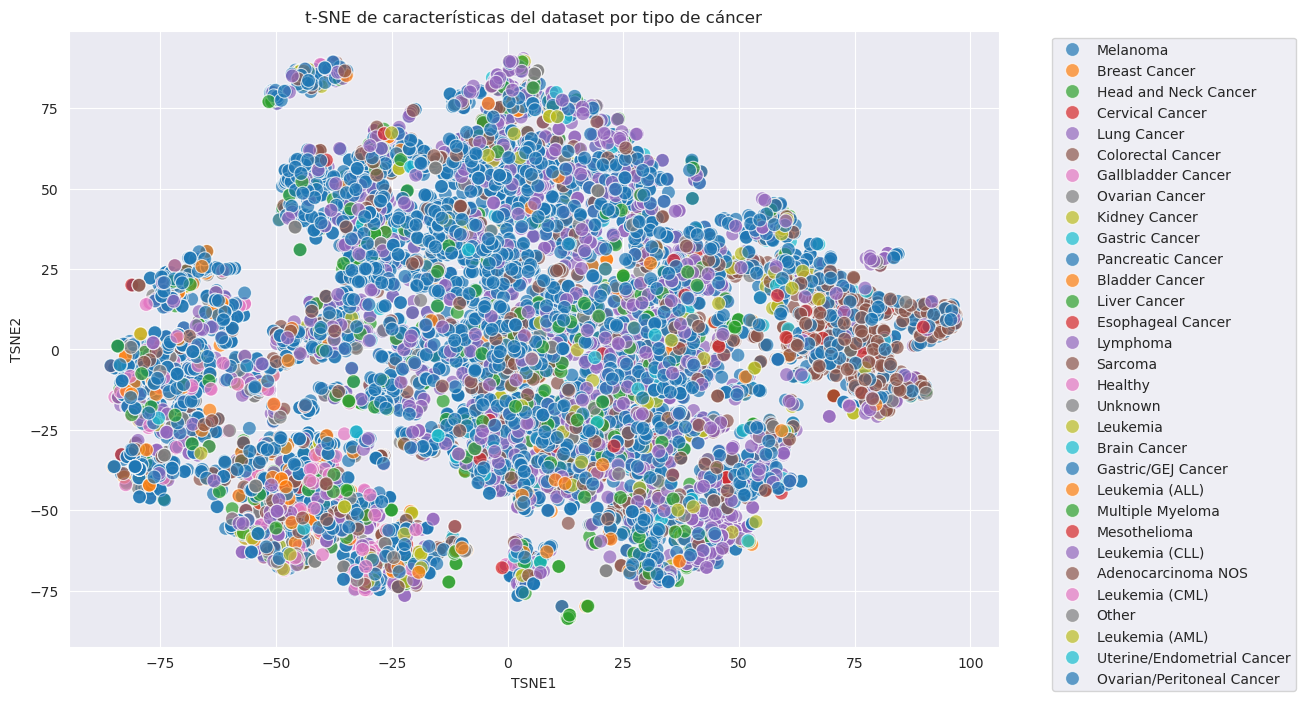

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
# Seleccionar las características numéricas para el análisis
features = df.select_dtypes(include=['float64', 'int64']).columns.tolist()
X = df[features]
# Estandarizar las características
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
# Aplicar t-SNE para reducción de dimensionalidad
tsne = TSNE(n_components=2, random_state=42)
X_tsne = tsne.fit_transform(X_scaled)
# Crear un DataFrame con los resultados de t-SNE
tsne_df = pd.DataFrame(data=X_tsne, columns=['TSNE1', 'TSNE2'])
tsne_df['Cancer_Type'] = df['Cancer_Type'].values
# Visualizar los resultados de t-SNE
plt.figure(figsize=(12, 8))
sns.scatterplot(x='TSNE1', y='TSNE2', hue='Cancer_Type', data=tsne_df, palette='tab10', s=100, alpha=0.7)
plt.title('t-SNE de características del dataset por tipo de cáncer')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()